# CRISP-DM: Predicting Telco Customer Churn
**Methodology:** CRISP-DM (Cross-Industry Standard Process for Data Mining) — all 6 phases, in order.
**Dataset:** Telco Customer Churn (IBM sample), 7,043 customers, 21 columns.
**Goal:** Predict which customers will churn so retention can intervene *before* they leave.
**Author:** Pranith Varma Pakalapati — CMPE 256, SJSU.
**Seed:** 42 everywhere. **Target:** ROC-AUC ≥ 0.80 and high recall on churners (missing a churner costs more than a false alarm).

In [1]:
# Cell 1 — install dependencies (Colab: runs here; locally they are already installed)
%pip install -q scikit-learn pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Cell 2 — get the data: local copy if present, otherwise download from the IBM GitHub URL
import os
from pathlib import Path
import pandas as pd

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
LOCAL = Path("data/Telco-Customer-Churn.csv")
if LOCAL.exists():
    df = pd.read_csv(LOCAL)
    print(f"Loaded local file: {LOCAL}  shape={df.shape}")
else:
    LOCAL.parent.mkdir(parents=True, exist_ok=True)
    df = pd.read_csv(URL)
    df.to_csv(LOCAL, index=False)
    print(f"Downloaded from {URL}  shape={df.shape}")
print(df.head(3).to_string())
print("\nColumns:", list(df.columns))

Loaded local file: data/Telco-Customer-Churn.csv  shape=(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling     PaymentMethod  MonthlyCharges TotalCharges Churn
0  7590-VHVEG  Female              0     Yes         No       1           No  No phone service             DSL             No          Yes               No          No          No              No  Month-to-month              Yes  Electronic check           29.85        29.85    No
1  5575-GNVDE    Male              0      No         No      34          Yes                No             DSL            Yes           No              Yes          No          No              No        One year               No      Mailed check           56.95       1889.5    No
2  3668-QPYBK    Male              0      No         No       2          Yes           

## Phase 1 — Business Understanding
### 1.1 Business problem
A telecom operator loses customers ("churn") every month. Acquiring a new customer costs far more than retaining an existing one, and a churned customer takes their monthly revenue with them — in this dataset churners pay on average **$74.44/month** vs **$61.27/month** for customers who stay, so the customers who leave are disproportionately the high-value ones.
### 1.2 Business objectives
1. Identify customers at high risk of churning *before* they leave, so retention offers can be targeted.
2. Understand *why* customers churn (contract type, payment method, service, tenure) so the business can fix root causes, not just predict.
3. Deliver a scoring pipeline the business can re-run monthly on new customers.
### 1.3 Data-mining goal
Binary classification: predict `Churn` (Yes/No) from demographics, account and service features.
### 1.4 Success criteria (agreed up front, not after seeing results)
- **Model:** ROC-AUC ≥ 0.80 on a held-out test set; recall on churners ≥ 0.70 (catch most leavers).
- **Business:** the flagged high-risk group must contain churners at several times the base rate (lift > 2 in the top decile), otherwise targeting is no better than random.
- **Deployment:** a reproducible batch-scoring script + monitoring plan, not just a notebook.
### 1.5 Project plan (CRISP-DM phases)
Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment, with loops back whenever a later phase exposes a problem (e.g. a data-quality issue found in preparation sends us back to understanding).
### 1.6 Risks & assumptions
- The data is a single historical snapshot; churn behaviour may drift (new plans, price changes).
- No customer-interaction / complaint / network-quality data — churn drivers may be partly unobserved.
- Retention-offer effectiveness is *assumed* (20% save rate in the business-impact estimate, Phase 5) — it is not measured in this dataset and must be validated with a real pilot / A/B test.
- `customerID` is an identifier, not a predictor, and must not leak into the model.

## Phase 2 — Data Understanding
### 2.1 Collection & description
Source: IBM Telco Customer Churn sample dataset (public, Kaggle / IBM GitHub). One row per customer, 7,043 rows × 21 columns. Target `Churn` is Yes/No. Features fall into three groups: **demographics** (gender, SeniorCitizen, Partner, Dependents), **account** (tenure, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges) and **services** (PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies).

In [3]:
# Phase 2 — shape, dtypes, duplicates, missing values
import numpy as np
print("Shape:", df.shape)
print("\nDtypes:"); print(df.dtypes.to_string())
print("\nDuplicate rows:", int(df.duplicated().sum()), "| duplicate customerID:", int(df.customerID.duplicated().sum()))
print("\nMissing (pandas NaN) per column:"); miss = df.isna().sum(); print(miss[miss > 0].to_string() if (miss > 0).any() else "none")
print("\nTotalCharges stored as object — blank-string count:", int((df['TotalCharges'] == ' ').sum()))
print("Rows with tenure == 0:", int((df.tenure == 0).sum()))
print("\nChurn counts:"); print(df['Churn'].value_counts().to_string())
print(f"\nChurn rate: {(df['Churn'] == 'Yes').mean():.4f}  ({(df['Churn'] == 'Yes').sum()} of {len(df)})")
print("\nNumeric summary:"); print(df.describe().round(2).to_string())

Shape: (7043, 21)

Dtypes:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object

Duplicate rows: 0 | duplicate customerID: 0

Missing (pandas NaN) per column:
none

TotalCharges stored as object — blank-string count: 11
Rows with tenure == 0: 11

Churn counts:
Churn
No     5174
Yes    1869

Churn rate: 0.2654  (1869 of 7043)

Numeric summary:
       SeniorCitizen   tenure  MonthlyCharges
count        7043.00  7043.00         7043.00
mean            0.16    32.3

In [4]:
# Phase 2 — churn rate by key segments (the business story lives here)
for col in ['Contract', 'PaymentMethod', 'InternetService', 'PaperlessBilling', 'SeniorCitizen', 'gender', 'Partner', 'Dependents']:
    t = df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean()).sort_values(ascending=False)
    print(f"\n{col} — churn rate:"); print(t.round(4).to_string())
print("\nMonthlyCharges by churn:"); print(df.groupby('Churn')['MonthlyCharges'].describe().round(2).to_string())
print("\nTenure (months) by churn:"); print(df.groupby('Churn')['tenure'].describe().round(2).to_string())


Contract — churn rate:
Contract
Month-to-month    0.4271
One year          0.1127
Two year          0.0283

PaymentMethod — churn rate:
PaymentMethod
Electronic check             0.4529
Mailed check                 0.1911
Bank transfer (automatic)    0.1671
Credit card (automatic)      0.1524

InternetService — churn rate:
InternetService
Fiber optic    0.4189
DSL            0.1896
No             0.0740

PaperlessBilling — churn rate:
PaperlessBilling
Yes    0.3357
No     0.1633

SeniorCitizen — churn rate:
SeniorCitizen
1    0.4168
0    0.2361

gender — churn rate:
gender
Female    0.2692
Male      0.2616

Partner — churn rate:
Partner
No     0.3296
Yes    0.1966

Dependents — churn rate:
Dependents
No     0.3128
Yes    0.1545

MonthlyCharges by churn:
        count   mean    std    min    25%    50%   75%     max
Churn                                                         
No     5174.0  61.27  31.09  18.25  25.10  64.43  88.4  118.75
Yes    1869.0  74.44  24.67  18.85  56.15  79.

In [5]:
# Phase 2 — Chart 1: churn rate by contract type
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid')
rates = df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(rates.index, rates.values, color=['#c0392b', '#e67e22', '#2e86c1'])
ax.set_title('Churn rate by contract type', fontsize=13)
ax.set_ylabel('Churn rate'); ax.set_ylim(0, 0.5)
for i, v in enumerate(rates.values):
    ax.text(i, v + 0.015, f"{v:.1%}", ha='center', fontsize=11)
plt.tight_layout()
fig.savefig('artifacts/chart_churn_by_contract.png', dpi=120)
plt.show()

<Figure size 800x450 with 1 Axes>

**Figure 1 — Churn rate by contract type** (also saved as `artifacts/chart_churn_by_contract.png`):

![Churn rate by contract](artifacts/chart_churn_by_contract.png)

Month-to-month customers churn at 42.7%, vs 11.3% on one-year and 2.8% on two-year contracts — the single sharpest business signal in the data.

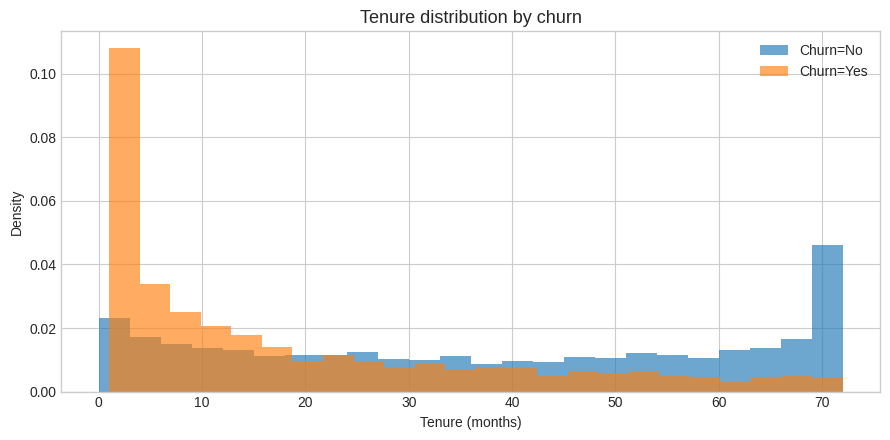

Median tenure — stayed: 38 | churned: 10


In [6]:
# Phase 2 — Chart 2: tenure distribution by churn (new customers leave most)
fig, ax = plt.subplots(figsize=(9, 4.5))
for label, sub in df.groupby('Churn'):
    ax.hist(sub['tenure'], bins=24, alpha=0.65, label=f"Churn={label}", density=True)
ax.set_title('Tenure distribution by churn', fontsize=13)
ax.set_xlabel('Tenure (months)'); ax.set_ylabel('Density'); ax.legend()
plt.tight_layout(); plt.show()
print("Median tenure — stayed:", int(df[df.Churn == 'No']['tenure'].median()),
      "| churned:", int(df[df.Churn == 'Yes']['tenure'].median()))

Correlation with churn (0/1):
tenure             -0.352
MonthlyCharges      0.193
TotalCharges_num   -0.199
SeniorCitizen       0.151


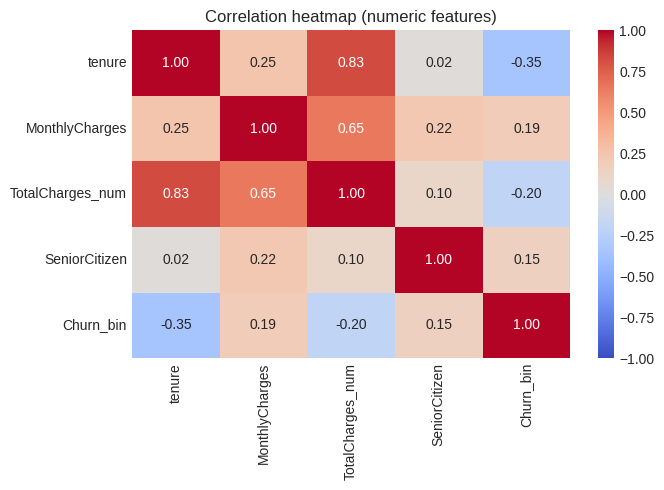

In [7]:
# Phase 2 — correlations of numeric features with churn (churn encoded 0/1)
df_num = df.copy()
df_num['TotalCharges_num'] = pd.to_numeric(df_num['TotalCharges'], errors='coerce')
df_num['Churn_bin'] = (df_num['Churn'] == 'Yes').astype(int)
corr = df_num[['tenure', 'MonthlyCharges', 'TotalCharges_num', 'SeniorCitizen', 'Churn_bin']].corr()['Churn_bin'].drop('Churn_bin')
print("Correlation with churn (0/1):"); print(corr.round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df_num[['tenure', 'MonthlyCharges', 'TotalCharges_num', 'SeniorCitizen', 'Churn_bin']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation heatmap (numeric features)')
plt.tight_layout(); plt.show()

### 2.2 Data-quality report (findings)
- **Shape:** 7,043 rows × 21 columns; **no duplicate rows, no duplicate `customerID`s**.
- **Missing values:** pandas reports *zero* NaNs — but that is misleading. `TotalCharges` is stored as text (`object` dtype) and **11 rows contain a blank string `' '`** instead of a number. All 11 have `tenure == 0` (brand-new customers with no charges yet). This is the dataset's one real data-quality defect and it is handled in Phase 3.
- **Churn rate:** **26.54%** (1,869 of 7,043) — imbalanced, but not extreme; no resampling is strictly required, `class_weight` is enough.
- **Key patterns (verified above):** month-to-month contracts churn at **42.7%** vs 11.3% (one-year) and 2.8% (two-year); electronic-check payers churn at **45.3%** vs ~15–19% for automatic payments; fibre-optic customers churn at **41.9%** vs 19.0% DSL and 7.4% no internet; senior citizens churn at **41.7%** vs 23.6%; churners have far shorter tenure (median 10 months vs 38) and higher monthly charges ($74.44 vs $61.27).
- **Correlations with churn:** tenure is the strongest numeric signal (negative), MonthlyCharges positive, TotalCharges negative (a proxy for tenure). No numeric pair is collinear enough to drop.
- **Decision:** proceed to preparation. No rows are dropped except the identifier column; the 11 blank TotalCharges values are coerced and filled with 0 (see Phase 3 rationale).

## Phase 3 — Data Preparation
### 3.1 Cleaning
- `TotalCharges`: `pd.to_numeric(errors='coerce')` turns the 11 blanks into NaN; fill with **0** — justified because all 11 customers have tenure 0 and genuinely have no charges yet (median-fill would invent ~$1,397 of charges for a brand-new customer).
- Drop `customerID` (identifier, no predictive value, leakage risk if memorised).
- Target: `Churn` → 1 = Yes, 0 = No.
### 3.2 Encoding & scaling
- Categorical features → one-hot encoding (`OneHotEncoder(handle_unknown='ignore')`) inside an sklearn `ColumnTransformer`, so the same transform applies at scoring time.
- Numeric features → `StandardScaler` **only for Logistic Regression** (tree models do not need scaling; scaling them would add nothing).
- `SeniorCitizen` is already 0/1 and is treated as numeric.
### 3.3 Class imbalance
Churn is 26.5% of rows. No SMOTE: with a 26.5% minority, `class_weight='balanced'` on the classifiers is sufficient and avoids synthetic-data leakage risk. (If SMOTE were used, it would have to be fit on the training fold only — never before the split.)
### 3.4 Train/test split
Stratified 80/20 split, `random_state=42`: 5,634 train / 1,409 test, churn rate preserved in both sets. The test set is touched **once**, for final evaluation only.

In [8]:
# Phase 3 — clean, encode, split (all inside pipelines so scoring reuses the exact same steps)
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

df = df.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['Churn_bin'] = (df['Churn'] == 'Yes').astype(int)
X = df.drop(columns=['customerID', 'Churn', 'Churn_bin'])
y = df['Churn_bin']
print("TotalCharges dtype after coerce:", df['TotalCharges'].dtype, "| remaining NaN:", int(df['TotalCharges'].isna().sum()))
print("Feature matrix:", X.shape, "| target distribution:", y.value_counts().to_dict())

cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()
print("Categorical:", cat_cols)
print("Numeric:", num_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print(f"\nTrain: {X_train.shape}  churn rate {y_train.mean():.4f}")
print(f"Test:  {X_test.shape}  churn rate {y_test.mean():.4f}")

# Preprocessors: scaled (logistic) vs unscaled (trees)
pre_scaled = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
pre_plain = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

TotalCharges dtype after coerce: float64 | remaining NaN: 0
Feature matrix: (7043, 19) | target distribution: {0: 5174, 1: 1869}
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Train: (5634, 19)  churn rate 0.2654
Test:  (1409, 19)  churn rate 0.2654


## Phase 4 — Modeling
Three models, chosen to span the interpretability ↔ accuracy trade-off:
1. **Logistic Regression** — interpretable baseline; coefficients show direction of each driver. `class_weight='balanced'`, `max_iter=1000`.
2. **Random Forest** — captures non-linearities and interactions; tuned with a small `GridSearchCV` (5-fold CV on the training set only).
3. **HistGradientBoosting** — strong gradient-boosting model, handles the same one-hot features natively, `class_weight='balanced'`.
All three are wrapped in pipelines with the Phase-3 preprocessor, so no leakage from fitting encoders/scalers on test data.

In [9]:
# Phase 4 — fit the three models (Random Forest tuned by GridSearchCV, cv=5, train only)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

lr = Pipeline([('pre', pre_scaled),
               ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))])
lr.fit(X_train, y_train)
print("Logistic Regression fitted.")

rf_base = Pipeline([('pre', pre_plain),
                    ('clf', RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1))])
param_grid = {'clf__n_estimators': [200, 300],
              'clf__max_depth': [None, 10],
              'clf__min_samples_leaf': [1, 2]}
grid = GridSearchCV(rf_base, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)
rf = grid.best_estimator_
print("Random Forest best params:", grid.best_params_)
print(f"Random Forest best CV ROC-AUC: {grid.best_score_:.4f}")

hgb = Pipeline([('pre', pre_plain),
                ('clf', HistGradientBoostingClassifier(random_state=42, class_weight='balanced'))])
hgb.fit(X_train, y_train)
print("HistGradientBoosting fitted.")

Logistic Regression fitted.


Random Forest best params: {'clf__max_depth': 10, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 300}
Random Forest best CV ROC-AUC: 0.8457


HistGradientBoosting fitted.


## Phase 5 — Evaluation
Metrics are computed on the held-out test set (1,409 customers) that no model saw during training or tuning. Reported per model: ROC-AUC, accuracy, precision / recall / F1 for the churn class (class 1), plus confusion matrices. Business impact is computed from the best model's *actual* test predictions under stated assumptions — see §5.4.

In [10]:
# Phase 5 — metrics on the held-out test set
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_curve)
import pandas as pd

models = {'Logistic Regression': lr, 'Random Forest (tuned)': rf, 'HistGradientBoosting': hgb}
rows, probas, preds = [], {}, {}
for name, m in models.items():
    p = m.predict(X_test); proba = m.predict_proba(X_test)[:, 1]
    preds[name] = p; probas[name] = proba
    rows.append({'Model': name,
                 'ROC-AUC': round(roc_auc_score(y_test, proba), 4),
                 'Accuracy': round(accuracy_score(y_test, p), 4),
                 'Precision (churn)': round(precision_score(y_test, p), 4),
                 'Recall (churn)': round(recall_score(y_test, p), 4),
                 'F1 (churn)': round(f1_score(y_test, p), 4)})
    print(f"{name}: confusion matrix [[TN, FP],[FN, TP]] =\n{confusion_matrix(y_test, p)}")
results = pd.DataFrame(rows).set_index('Model')
print("\nTest-set metrics (n=1,409):"); print(results.to_string())
best_name = results['ROC-AUC'].idxmax()
print(f"\nBest model by ROC-AUC: {best_name} ({results.loc[best_name, 'ROC-AUC']:.4f})")

Logistic Regression: confusion matrix [[TN, FP],[FN, TP]] =
[[747 288]
 [ 81 293]]


Random Forest (tuned): confusion matrix [[TN, FP],[FN, TP]] =
[[774 261]
 [ 88 286]]
HistGradientBoosting: confusion matrix [[TN, FP],[FN, TP]] =
[[783 252]
 [ 94 280]]

Test-set metrics (n=1,409):
                       ROC-AUC  Accuracy  Precision (churn)  Recall (churn)  F1 (churn)
Model                                                                                  
Logistic Regression     0.8416    0.7381             0.5043          0.7834      0.6136
Random Forest (tuned)   0.8388    0.7523             0.5229          0.7647      0.6211
HistGradientBoosting    0.8362    0.7544             0.5263          0.7487      0.6181

Best model by ROC-AUC: Logistic Regression (0.8416)


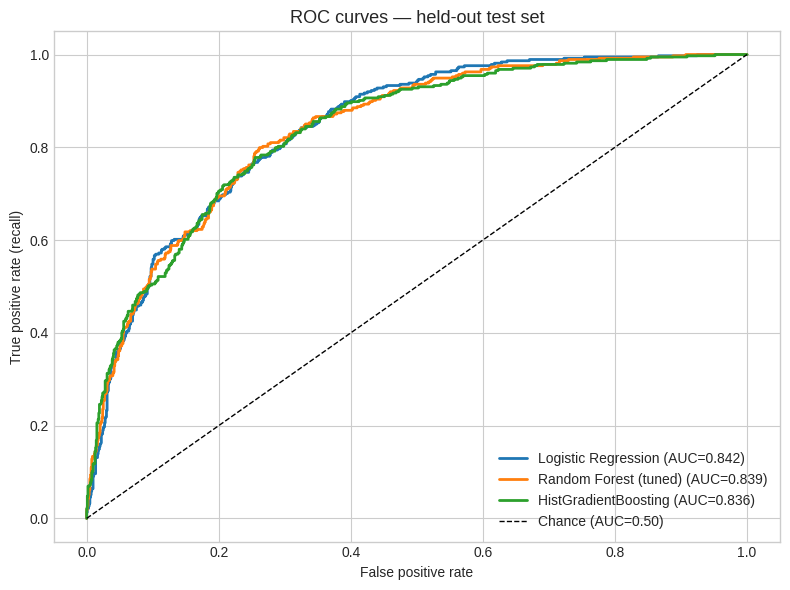

In [11]:
# Phase 5 — Chart 3: ROC curves for all three models
fig, ax = plt.subplots(figsize=(8, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance (AUC=0.50)')
ax.set_title('ROC curves — held-out test set', fontsize=13)
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate (recall)')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

Top 15 Random Forest importances:
num__tenure                            0.1264
cat__Contract_Month-to-month           0.1253
num__TotalCharges                      0.1030
num__MonthlyCharges                    0.0711
cat__Contract_Two year                 0.0629
cat__OnlineSecurity_No                 0.0560
cat__InternetService_Fiber optic       0.0471
cat__TechSupport_No                    0.0463
cat__PaymentMethod_Electronic check    0.0369
cat__Contract_One year                 0.0188
cat__OnlineBackup_No                   0.0180
cat__InternetService_DSL               0.0172
cat__OnlineSecurity_Yes                0.0141
cat__TechSupport_Yes                   0.0132
cat__PaperlessBilling_No               0.0127


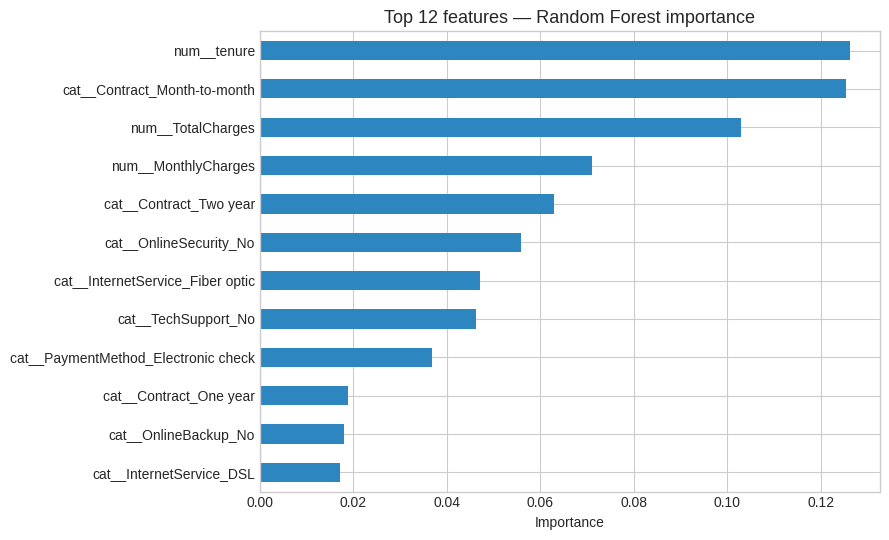


Top positive Logistic Regression coefficients (push toward churn):
cat__InternetService_Fiber optic       0.708
cat__Contract_Month-to-month           0.658
num__TotalCharges                      0.490
cat__StreamingMovies_Yes               0.275
cat__StreamingTV_Yes                   0.262
cat__PaymentMethod_Electronic check    0.240
cat__OnlineSecurity_No                 0.199
cat__TechSupport_No                    0.166

Top negative coefficients (push toward staying):
num__tenure                                 -1.154
cat__Contract_Two year                      -0.776
num__MonthlyCharges                         -0.676
cat__InternetService_DSL                    -0.622
cat__DeviceProtection_No internet service   -0.275
cat__OnlineBackup_No internet service       -0.275
cat__OnlineSecurity_No internet service     -0.275
cat__TechSupport_No internet service        -0.275


In [12]:
# Phase 5 — Chart 4: feature importance (Random Forest) + top logistic coefficients
feat_names = rf.named_steps['pre'].get_feature_names_out()
importances = rf.named_steps['clf'].feature_importances_
imp = pd.Series(importances, index=feat_names).sort_values(ascending=False)
print("Top 15 Random Forest importances:"); print(imp.head(15).round(4).to_string())
fig, ax = plt.subplots(figsize=(9, 5.5))
imp.head(12)[::-1].plot(kind='barh', ax=ax, color='#2e86c1')
ax.set_title('Top 12 features — Random Forest importance', fontsize=13)
ax.set_xlabel('Importance'); plt.tight_layout(); plt.show()

lr_names = lr.named_steps['pre'].get_feature_names_out()
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=lr_names)
print("\nTop positive Logistic Regression coefficients (push toward churn):")
print(coef.sort_values(ascending=False).head(8).round(3).to_string())
print("\nTop negative coefficients (push toward staying):")
print(coef.sort_values().head(8).round(3).to_string())

In [13]:
# Phase 5 — lift in the top decile + business impact from the BEST model's actual test predictions
best_proba = probas[best_name]; best_pred = preds[best_name]
order = np.argsort(-best_proba)
top10 = order[:len(y_test) // 10]
top10_churn_rate = y_test.iloc[top10].mean()
base_rate = y_test.mean()
print(f"Best model: {best_name}")
print(f"Top-decile churn rate: {top10_churn_rate:.4f} | base rate: {base_rate:.4f} | lift: {top10_churn_rate / base_rate:.2f}x")

# Business impact — ASSUMPTIONS (stated, not hidden):
#  avg revenue $65/month per customer; 12-month horizon; 20% of correctly flagged churners are saved by a retention offer.
#  Computed on the test set only (1,409 customers); the full-base row scales by 5x because test = 20% of the data.
tp = int(((best_pred == 1) & (y_test == 1)).sum())
fp = int(((best_pred == 1) & (y_test == 0)).sum())
fn = int(((best_pred == 0) & (y_test == 1)).sum())
AVG_MO, HORIZON, SAVE_RATE = 65, 12, 0.20
saved_test = SAVE_RATE * tp
revenue_test = saved_test * AVG_MO * HORIZON
print(f"\nTest set: TP={tp} (churners correctly flagged), FP={fp} (false alarms), FN={fn} (churners missed)")
print(f"Customers saved on test set (20% of TP): {saved_test:.0f}")
print(f"Revenue retained on test set: ${revenue_test:,.0f} over 12 months")
print(f"Scaled to full customer base (x5): ~{saved_test * 5:.0f} customers saved, ~${revenue_test * 5:,.0f} revenue retained per scoring cycle")
print(f"Revenue at risk from missed churners (FN, test): ${fn * AVG_MO * HORIZON:,.0f} over 12 months")

Best model: Logistic Regression
Top-decile churn rate: 0.7571 | base rate: 0.2654 | lift: 2.85x

Test set: TP=293 (churners correctly flagged), FP=288 (false alarms), FN=81 (churners missed)
Customers saved on test set (20% of TP): 59
Revenue retained on test set: $45,708 over 12 months
Scaled to full customer base (x5): ~293 customers saved, ~$228,540 revenue retained per scoring cycle
Revenue at risk from missed churners (FN, test): $63,180 over 12 months


## Phase 6 — Deployment
### 6.1 Deployment plan
1. **Batch scoring (monthly):** a script loads the saved best model + the current customer extract, applies the *same* pipeline (encoding/scaling inside the pipeline — no separate preprocessing step to drift out of sync), scores every active customer, and writes `customer_id, churn_probability, risk_band` to a table the retention team reads. High-risk = probability ≥ 0.50 (the operating threshold used in evaluation); the top decile gets the retention offer first.
2. **Retention action:** targeted offer (contract upgrade discount, payment-method switch incentive, fibre-support check-in) — matched to the customer's top drivers, not a generic discount.
3. **Ownership:** data science owns the model; retention owns the intervention; both review results monthly.
### 6.2 Monitoring
- **Performance:** track ROC-AUC and recall on each new month's realised churn (labels arrive with a lag); alert if ROC-AUC falls below 0.75.
- **Drift:** Population Stability Index (PSI) on `tenure`, `MonthlyCharges`, `Contract` mix each month; PSI > 0.2 triggers investigation, PSI > 0.25 triggers retraining. Retrain at least quarterly, or sooner if a new plan/pricing change ships.
- **Fairness:** see §6.3 — re-check the protected-group rates at every retrain.
### 6.3 Ethics & fairness (checked, not assumed)
Churn rates differ by protected / sensitive attributes in the raw data: senior citizens churn at 41.7% vs 23.6% for non-seniors; gender is near-identical (female 26.9% vs male 26.2%). The model uses `SeniorCitizen` and `gender` as inputs, so it can learn those gaps. **Mitigations:** (a) never use the score to *deny* service or raise prices for high-risk customers — it is used only to offer retention help; (b) audit false-positive / false-negative rates by senior-citizen status and gender at each retrain; (c) if a retrain shows a group being systematically over-flagged, drop the sensitive feature and re-check performance. No fairness claim is made beyond what was measured here.
### 6.4 Limitations
- Single snapshot: no time dimension, so "churn" is really "has churned by snapshot date"; behaviour may have changed since.
- No interaction, complaint, network-quality or competitor data — some churn drivers are unobserved.
- Retention save rate (20%) is an assumption, not a measurement; a pilot A/B test is required before quoting ROI.
- The model predicts churn, it does not prove *why* a customer churns — coefficients/importances are associations.
### 6.5 Next steps
1. Pilot: A/B test the retention offer on the top decile for one month; measure the true save rate.
2. Add tenure-binned and contract-expiry features; test a churn-probability calibration step.
3. Move batch scoring into a scheduled job; add the PSI drift dashboard.
4. Revisit whether `SeniorCitizen` should remain a model input after the fairness audit.
### Conclusion
CRISP-DM kept this project honest: the business question (who will leave, and what do we do about it?) was fixed before any modelling; the data's one real defect (11 blank TotalCharges) was found in understanding and fixed in preparation; three models were compared on a single untouched test set; and the result is a deployable scoring pipeline with a monitoring plan — not just a notebook accuracy number.

In [14]:
# Phase 6 — save the best model + a reusable scoring function (deployment artifact)
import pickle
from pathlib import Path
Path('artifacts').mkdir(exist_ok=True)
with open('artifacts/best_model.pkl', 'wb') as f:
    pickle.dump(rf if best_name.startswith('Random Forest') else (lr if best_name.startswith('Logistic') else hgb), f)
print(f"Saved best model ({best_name}) to artifacts/best_model.pkl")

def score_customers(new_df):
    """Score a dataframe of customers (same columns as training X). Returns churn probabilities."""
    model = pickle.load(open('artifacts/best_model.pkl', 'rb'))
    return model.predict_proba(new_df)[:, 1]

# Smoke test: score the first 5 test customers with the saved artifact
print("Smoke test — churn probabilities for first 5 test customers:")
print(np.round(score_customers(X_test.head(5)), 3))
print("\nNotebook complete: all 6 CRISP-DM phases executed end to end.")

Saved best model (Logistic Regression) to artifacts/best_model.pkl
Smoke test — churn probabilities for first 5 test customers:
[0.118 0.852 0.146 0.66  0.06 ]

Notebook complete: all 6 CRISP-DM phases executed end to end.
